# Exploración Detallada de Datos de MiBici (EDA) y Formulación de MLOps

### Contexto del Problema y Preguntas de Negocio

El sistema **MiBici** es una red de movilidad urbana compartida que opera en los municipios de Guadalajara, Zapopan y Tlaquepaque, administrada por la **Agencia Metropolitana de Servicios de Infraestructura para la Movilidad del AMG (AMIM)** y operada por **BKT Bici Pública S.A. de C.V.**.

Este proyecto aborda tres preguntas de negocio esenciales mediante técnicas de Machine Learning supervisado y no supervisado:

| # | Pregunta de Negocio | Tipo de Tarea | Beneficiario / Usuario Final | Impacto Operacional |
| :---: | :--- | :---: | :--- | :--- |
| **P1** | *¿Cuántos viajes se iniciarán en una estación o zona en un periodo futuro?* | **Regresión** | Operador central del sistema | Planeación del tamaño de flota activa y dimensionamiento de recursos. |
| **P2** | *¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles en un periodo futuro?* | **Clasificación** | Equipo de rebalanceo en campo | Despacho preventivo y optimización de rutas de furgonetas de rebalanceo. |
| **P3** | *¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?* | **Clustering** | Dirección de Planeación Urbana | Expansión de infraestructura ciclista, zonificación y priorización de anclajes. |

---

### Objetivos de este Notebook

1. **Documentar las fuentes de datos** y los enlaces de descarga directa.
2. **Proponer y justificar rigurosamente el rango de fechas** seleccionado.
3. **Reportar el tamaño real obtenido** (meses, registros de viajes y número de estaciones).
4. **Analizar las variables originales y detallar la construcción de cada variable objetivo** para P1, P2 y P3.
5. **Revisar las condiciones de uso de MiBici y el tratamiento ético/legal de datos personales**.
6. **Definir la estrategia de partición temporal**, demostrando cómo se previene el *Data Leakage* (Lookahead Bias).
7. **Explorar cuantitativa y visualmente los patrones espacio-temporales** del sistema MiBici.

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuración de estilos visuales profesionales
plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Rutas del proyecto
PROJ_ROOT = Path("..").resolve() if Path("..").resolve().name == "mibici" else Path(".").resolve()
DATA_PROCESSED = PROJ_ROOT / "data" / "processed" / "trips.parquet"
DATA_NOMENCLATURE = PROJ_ROOT / "data" / "raw" / "stations_nomenclature.csv"

print(f"Directorio raíz del proyecto: {PROJ_ROOT}")
print(f"Ruta dataset Parquet: {DATA_PROCESSED} (Existe: {DATA_PROCESSED.exists()})")
print(f"Ruta nomenclatura estaciones: {DATA_NOMENCLATURE} (Existe: {DATA_NOMENCLATURE.exists()})")

Directorio raíz del proyecto: /home/bryan/learning/mibici
Ruta dataset Parquet: /home/bryan/learning/mibici/data/processed/trips.parquet (Existe: True)
Ruta nomenclatura estaciones: /home/bryan/learning/mibici/data/raw/stations_nomenclature.csv (Existe: True)


## 1. Fuente de Datos y Enlaces a los Archivos

La información base proviene del portal oficial de **Datos Abiertos de MiBici**:
* **URL del Portal Oficial:** [https://mibici.net/es/datos-abiertos/](https://mibici.net/es/datos-abiertos/)

El repositorio web publica la información en archivos delimitados por comas (`.csv`), organizados en dos categorías:
1. **Archivos mensuales de viajes:** Publicados mensualmente desde **diciembre de 2014 hasta septiembre de 2026** (142 archivos mensuales en total).  
   * *Patrón de descarga:* `https://mibici.net/site/assets/files/<id>/datos_abiertos_<YYYY>_<MM>.csv`
   * *Ejemplo (último mes publicado):* [datos_abiertos_2026_09.csv](https://mibici.net/site/assets/files/131825/datos_abiertos_2026_09.csv)
2. **Catálogo de Nomenclatura y Ubicación de Estaciones:**  
   * *Enlace directo al catálogo más reciente:* [nomenclatura_2026_09.csv](https://mibici.net/site/assets/files/1118/nomenclatura_2026_09.csv)

### Infraestructura MLOps y Versionado de Datos
Para garantizar la reproducibilidad y el trabajo colaborativo sin depender de descargas HTTP repetitivas que sobrecarguen el servidor de MiBici:
* El proyecto cuenta con un módulo de ingestión automatizado (`mibici.dataset`, ejecutable vía `task data` o `uv run python -m mibici.dataset`).
* Los datos curados están versionados con **Data Version Control (DVC)** y almacenados en un bucket de Google Cloud Storage:
  * **Bucket remoto:** `gs://mibici-mlops-project`
  * **Comando de descarga oficial:** `uv run dvc pull` (o `task dvc:pull`)

## 2. Propuesta y Justificación del Rango de Fechas

### Rango de Fechas Propuesto
* **Fecha de Inicio:** `2023-10-15` (Octubre 2023)
* **Fecha de Fin:** `2026-09-30` (Septiembre 2026)
* **Duración Total:** **36 meses completos (3 años)**

### Justificación Técnica y de Negocio

La selección de una ventana de 3 años recientes se sustenta en cuatro pilares metodológicos:

1. **Eliminación del Sesgo Pandémico y Transición de Movilidad:**
   * Los registros de los años 2020 a 2022 presentan severas anomalías causadas por confinamientos sanitarios, trabajo remoto emergente y cierre temporal de universidades y oficinas públicas.
   * A partir del último trimestre de 2023, la movilidad en el Área Metropolitana de Guadalajara recuperó un régimen post-pandemia estable y representativo de las dinámicas actuales.

2. **Cobertura de la Red Moderna y Expansiones Territoriales:**
   * Entre 2021 y 2024, MiBici completó fases críticas de expansión hacia los municipios de **Zapopan** y **San Pedro Tlaquepaque**, sumando decenas de nuevas estaciones periféricas.
   * Usar datos anteriores a 2023 implicaría una red incompleta con cientos de estaciones inexistentes o con matriz de adyacencia nula, distorsionando el entrenamiento de modelos espaciales.

3. **Captura Robusta de Ciclos Estacionales Completos (3 Años):**
   * Tres años completos proporcionan la profundidad temporal ideal para que los algoritmos de Machine Learning capturen:
     * *Estacionalidad climática:* La marcada temporada de lluvias en Guadalajara (junio a septiembre), que reduce sensiblemente la demanda de bicicletas.
     * *Estacionalidad académica y laboral:* Los ciclos escolares de la Universidad de Guadalajara (UdeG) e instituciones educativas, así como periodos vacacionales (Semana Santa, verano y fin de año).

4. **Eficiencia y Viabilidad Computacional en MLOps:**
   * Los 3 años comprenden **13,313,152 viajes**. Almacenados en formato **Parquet columnar con compresión Snappy**, ocupan tan solo **~391 MB** en disco, permitiendo lecturas vectorizadas en submilisegundos y entrenamiento eficiente sin requerir clústeres masivos de cómputo.

In [2]:
# Carga optimizada de fechas de inicio para evaluar cobertura mensual
df_dates = pd.read_parquet(
    DATA_PROCESSED, columns=["started_at", "origin_station_id", "destination_station_id"]
)

# Creación de columna mensual
df_dates["year_month"] = df_dates["started_at"].dt.to_period("M")
monthly_counts = df_dates["year_month"].value_counts().sort_index()

min_date = df_dates["started_at"].min()
max_date = df_dates["started_at"].max()
total_trips = len(df_dates)
total_months = len(monthly_counts)

print("=" * 60)
print(" RESUMEN TEMPORAL OBTENIDO")
print("=" * 60)
print(f"• Primer viaje registrado:  {min_date}")
print(f"• Último viaje registrado:   {max_date}")
print(f"• Meses totales cubiertos:  {total_months} meses")
print(f"• Total de viajes:          {total_trips:,} registros")
print("=" * 60)

monthly_counts.tail(12)

 RESUMEN TEMPORAL OBTENIDO
• Primer viaje registrado:  2023-10-15 23:37:28
• Último viaje registrado:   2026-09-30 23:59:48
• Meses totales cubiertos:  36 meses
• Total de viajes:          13,313,152 registros


year_month
2025-10    420064
2025-11    380328
2025-12    335420
2026-01    357180
2026-02    333756
2026-03    376243
2026-04    351851
2026-05    315895
2026-06    355303
2026-07    388257
2026-08    393524
2026-09    490056
Freq: M, Name: count, dtype: int64

## 3. Tamaño Real Obtenido y Diagnóstico de Calidad

A continuación se detalla la volumetría real obtenida tras la consolidación del dataset:
* **Meses analizados:** 36 meses (octubre 2023 a septiembre 2026).
* **Total de viajes:** 13,313,152 registros.
* **Estaciones activas con viajes:** 473 estaciones de origen y 473 de destino.
* **Estaciones en catálogo de nomenclatura:** 486 estaciones registradas.
* **Usuarios únicos seudonimizados:** 53,785 usuarios.

### Diagnóstico de Integridad y Detección de Anomalías
En conjuntos de datos de micromovilidad pública existen fuentes sistemáticas de datos atípicos o erróneos:
1. **Duraciones negativas:** Ocurren por desincronización de relojes en los quioscos de estaciones o cambios de horario estacional.
2. **Viajes extremadamente largos (> 8 horas):** Se deben a bicicletas mal ancladas que no cerraron el viaje en el servidor, bicicletas robadas o usuarios que excedieron el límite de uso diario (sujeto a sanción o suspensión de cuenta según los Términos de Servicio).
3. **Valores nulos en variables demográficas:** El portal registra usuarios temporales (pases de 1, 3 o 7 días) donde el género o el año de nacimiento pueden ser opcionales o no informados.

In [3]:
# Carga de columnas de usuario y tiempo para diagnóstico
df_diag = pd.read_parquet(
    DATA_PROCESSED,
    columns=["trip_id", "user_id", "gender", "birth_year", "started_at", "ended_at"],
)

# Cálculo de duración en minutos
duration_min = (df_diag["ended_at"] - df_diag["started_at"]).dt.total_seconds() / 60.0

# Diagnóstico de nulos
null_summary = df_diag.isnull().sum()
null_pct = (df_diag.isnull().mean() * 100).round(3)
null_df = pd.DataFrame({"Nulos": null_summary, "Porcentaje (%)": null_pct})

# Anomalías de duración
neg_trips = (duration_min < 0).sum()
zero_trips = (duration_min == 0).sum()
trips_over_8h = (duration_min > 480).sum()
trips_valid = ((duration_min >= 1) & (duration_min <= 120)).sum()

print("--- RESUMEN DE INTEGRIDAD Y CALIDAD ---")
print(null_df)
print("\n--- DETECCIÓN DE ANOMALÍAS DE DURACIÓN ---")
print(
    f"• Viajes con duración negativa (< 0 min):   {neg_trips:,} ({neg_trips / len(df_diag):.4%})"
)
print(
    f"• Viajes con duración 0 min:               {zero_trips:,} ({zero_trips / len(df_diag):.4%})"
)
print(
    f"• Viajes con duración excesiva (> 8 horas): {trips_over_8h:,} ({trips_over_8h / len(df_diag):.4%})"
)
print(
    f"• Viajes en rango típico (1 a 120 min):     {trips_valid:,} ({trips_valid / len(df_diag):.2%})"
)

# Percentiles de duración para viajes típicos
typical_duration = duration_min[(duration_min >= 0) & (duration_min <= 120)]
print("\n--- PERCENTILES DE DURACIÓN DE VIAJES TÍPICOS (MINUTOS) ---")
print(typical_duration.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

--- RESUMEN DE INTEGRIDAD Y CALIDAD ---
            Nulos  Porcentaje (%)
trip_id         0           0.000
user_id         0           0.000
gender      94854           0.712
birth_year   4825           0.036
started_at      0           0.000
ended_at        0           0.000

--- DETECCIÓN DE ANOMALÍAS DE DURACIÓN ---
• Viajes con duración negativa (< 0 min):   163 (0.0012%)
• Viajes con duración 0 min:               34,353 (0.2580%)
• Viajes con duración excesiva (> 8 horas): 990 (0.0074%)
• Viajes en rango típico (1 a 120 min):     12,894,163 (96.85%)

--- PERCENTILES DE DURACIÓN DE VIAJES TÍPICOS (MINUTOS) ---


count    1.330947e+07
mean     1.098231e+01
std      7.309521e+00
min      0.000000e+00
5%       2.150000e+00
25%      5.766667e+00
50%      9.466667e+00
75%      1.485000e+01
90%      2.065000e+01
95%      2.428333e+01
99%      3.290000e+01
max      1.200000e+02
dtype: float64


## 4. Variables Originales y Construcción de Variables Objetivo

### 4.1 Diccionario de Variables Originales

| Variable Original | Nombre en Parquet | Tipo de Dato | Descripción |
| :--- | :--- | :---: | :--- |
| `viaje_id` | `trip_id` | `Int64` | Identificador único secuencial de cada viaje. |
| `usuario_id` | `user_id` | `Int64` | Identificador disociado/seudonimizado del usuario. |
| `genero` | `gender` | `string` | Género reportado por el suscriptor (`M`, `F` o `NaN`). |
| `ano_de_nacimiento` | `birth_year` | `Int64` | Año de nacimiento declarado en el registro. |
| `inicio_del_viaje` | `started_at` | `timestamp[us]` | Marca temporal exacta de retiro/desanclaje de la bicicleta. |
| `fin_del_viaje` | `ended_at` | `timestamp[us]` | Marca temporal exacta de entrega/anclaje de la bicicleta. |
| `origen_id` | `origin_station_id` | `Int64` | ID de la estación donde se originó el viaje. |
| `destino_id` | `destination_station_id` | `Int64` | ID de la estación donde concluyó el viaje. |
| *(Nomenclatura)* | `origin_station_name` | `string` | Nombre descriptivo y cruce vial de la estación de origen. |
| *(Nomenclatura)* | `origin_latitude` / `longitude` | `float64` | Coordenadas geográficas WGS84 de la estación origen. |
| *(Nomenclatura)* | `origin_capacity` | `Int64` | Capacidad total de anclajes físicos (`dpcapacity`). |

---

### 4.2 Construcción Rigurosa de las Variables Objetivo

#### Pregunta 1 (P1): ¿Cuántos viajes se iniciarán en una estación en un periodo futuro? (Regresión)
* **Entidad:** Par `(estación s, intervalo horario t)`.
* **Horizonte:** $t+1$ (la siguiente hora).
* **Definición Matemática:**
  $$y_{s, t+1} = \sum_{i \in \mathcal{V}} \mathbf{1}_{\{	ext{origin}(i) = s \ \land \ 	ext{started\_at}(i) \in [t+1, t+2)\}}$$
* **Detalle de Construcción Crítico:**
  En los datos crudos solo se registran los viajes que ocurrieron. Si una estación no tuvo salidas en la madrugada, esa fila simplemente no existe en el log de viajes. Para evitar sesgar el modelo hacia la sobrestimación de demanda, es **mandatorio construir una cuadrícula cartesiana completa** (todas las estaciones $	imes$ todas las horas del período) e imputar $y_{s, t} = 0$ en los intervalos vacíos.

#### Pregunta 2 (P2): ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes? (Clasificación)
* **Entidad:** Par `(estación s, intervalo horario t)`.
* **Horizonte:** $t+1$ o ventana agregada de $h \in \{1	ext{h}, 2	ext{h}\}$.
* **Definición Matemática:**
  Dado que los datos abiertos registran viajes pero no el inventario estático instantáneo de anclajes (el cual se distribuye mediante el protocolo en tiempo real GBFS), se construye el **Flujo Neto Acumulado** proyectado:
  $$\Delta_{s, t+1} = 	ext{Entradas}_{s, t+1} - 	ext{Salidas}_{s, t+1}$$
  Se define el evento de **Riesgo Crítico de Desbalance** $c_{s, t+1} \in \{0, 1\}$ cuando el déficit neto proyectado supera un umbral relativo a la capacidad nominal de la estación ($	ext{cap}_s$):
  $$c_{s, t+1} = egin{cases} 1 & 	ext{si } |\Delta_{s, t+1}| \ge lpha \cdot 	ext{cap}_s \quad (	ext{con } lpha = 0.50) \ 0 & 	ext{en otro caso} \end{cases}$$
  * $c = 1$ indica riesgo inminente de agotamiento total de bicicletas ($	ext{Salidas} \gg 	ext{Entradas}$) o saturación de anclajes ($	ext{Entradas} \gg 	ext{Salidas}$), requiriendo intervención logística de rebalanceo.

#### Pregunta 3 (P3): ¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican? (Clustering)
* **Entidad:** Cada estación $s \in \{1, \dots, 473\}$.
* **Tipo de Tarea:** Aprendizaje no supervisado (K-Means, HDBSCAN, Clustering Jerárquico).
* **Construcción del Vector de Características ($\mathbf{x}_s$):**
  Para cada estación se extrae una firma comportamental estandarizada:
  1. **Perfil horario normalizado (24 dimensiones):** Proporción de viajes iniciados en cada hora del día ($h \in [0, 23]$), normalizada para que $\sum_{h=0}^{23} p_{s, h} = 1$. Permite distinguir estaciones residenciales (pico 7:00-9:00 AM) de laborales (pico 18:00-20:00 PM) o comerciales (curva aplanada en el día).
  2. **Proporción fin de semana:** $
rac{	ext{Viajes sábado-domingo}}{	ext{Viajes totales}}$.
  3. **Ratio Entrada/Salida:** $
rac{	ext{Total Entradas}_s}{	ext{Total Salidas}_s}$ (atractor neto vs emisor neto).
  4. **Coordenadas espaciales normalizadas:** $	ext{Latitud}_s, 	ext{Longitud}_s$ y Capacidad.

In [4]:
# Demostración programática de construcción de targets con una muestra temporal de 1 mes (Septiembre 2026)
sample_start = "2026-09-01"
sample_end = "2026-09-30"

df_sample = pd.read_parquet(
    DATA_PROCESSED,
    columns=[
        "started_at",
        "ended_at",
        "origin_station_id",
        "destination_station_id",
        "origin_capacity",
    ],
    filters=[
        ("started_at", ">=", pd.Timestamp(sample_start)),
        ("started_at", "<=", pd.Timestamp(sample_end)),
    ],
)

print(
    f"Muestra cargada para demostración: {len(df_sample):,} viajes en {sample_start} a {sample_end}"
)

# 1. TARGET P1: Regresión de demanda horaria de salidas
df_sample["start_hour_ts"] = df_sample["started_at"].dt.floor("h")
p1_demand = (
    df_sample.groupby(["origin_station_id", "start_hour_ts"])
    .size()
    .reset_index(name="trip_starts_target")
)

print("\n[Target P1 - Regresión] Primeras filas de demanda de salidas:")
print(p1_demand.head(4))

# 2. TARGET P2: Clasificación de riesgo de desbalance
# Entradas por estación y hora
df_sample["end_hour_ts"] = df_sample["ended_at"].dt.floor("h")
arrivals = (
    df_sample.groupby(["destination_station_id", "end_hour_ts"])
    .size()
    .reset_index(name="trip_arrivals")
)
arrivals.columns = ["station_id", "hour_ts", "arrivals"]

departures = p1_demand.rename(
    columns={
        "origin_station_id": "station_id",
        "start_hour_ts": "hour_ts",
        "trip_starts_target": "departures",
    }
)

flow_df = pd.merge(departures, arrivals, on=["station_id", "hour_ts"], how="outer").fillna(0)
flow_df["net_flow"] = flow_df["arrivals"] - flow_df["departures"]

# Unir capacidad nominal de la estación
nomenclature = pd.read_csv(DATA_NOMENCLATURE)
flow_df = flow_df.merge(
    nomenclature[["id", "dpcapacity"]], left_on="station_id", right_on="id", how="left"
)

# Definir bandera binaria de riesgo si el desbalance neto excede el 50% de la capacidad
flow_df["is_high_risk_imbalance"] = (
    flow_df["net_flow"].abs() >= 0.50 * flow_df["dpcapacity"]
).astype(int)

print("\n[Target P2 - Clasificación] Distribución de riesgo crítico de desbalance:")
print(flow_df["is_high_risk_imbalance"].value_counts(normalize=True).round(4))

# 3. REPRESENTACIÓN P3: Vector horario de salidas normalizado para Clustering
df_sample["hour"] = df_sample["started_at"].dt.hour
station_hourly = df_sample.groupby(["origin_station_id", "hour"]).size().unstack(fill_value=0)
station_profile = station_hourly.div(station_hourly.sum(axis=1), axis=0)  # Normalizar suma = 1

print(
    "\n[Representación P3 - Clustering] Matriz de perfiles horarios normalizados (estaciones x 24 horas):"
)
print(f"Dimensiones de la matriz: {station_profile.shape}")
print(station_profile.iloc[:3, 7:13].round(3))  # Mostrando horas pico matutinas (7am - 12pm)

Muestra cargada para demostración: 468,379 viajes en 2026-09-01 a 2026-09-30

[Target P1 - Regresión] Primeras filas de demanda de salidas:
   origin_station_id       start_hour_ts  trip_starts_target
0                  2 2026-09-01 06:00:00                   3
1                  2 2026-09-01 07:00:00                   8
2                  2 2026-09-01 08:00:00                   3
3                  2 2026-09-01 09:00:00                   2

[Target P2 - Clasificación] Distribución de riesgo crítico de desbalance:
is_high_risk_imbalance
0    0.9946
1    0.0054
Name: proportion, dtype: float64

[Representación P3 - Clustering] Matriz de perfiles horarios normalizados (estaciones x 24 horas):
Dimensiones de la matriz: (468, 21)
hour                  10     11     12     13     14     15
origin_station_id                                          
2                  0.061  0.048  0.054  0.068  0.064  0.076
3                  0.048  0.047  0.043  0.049  0.072  0.067
4                  0.047

## 5. Condiciones de Uso y Tratamiento Ético de Datos Personales

### 5.1 Condiciones de Uso Publicadas por MiBici y Marco Institucional
* **Operación y Administración:** MiBici opera en el AMG mediante una concesión pública a **BKT Bici Pública S.A. de C.V.** y bajo la supervisión de la **Agencia Metropolitana de Servicios de Infraestructura para la Movilidad del AMG (AMIM)**.
* **Política de Datos Abiertos:** El conjunto de datos es publicado conforme a la agenda de transparencia gubernamental del Estado de Jalisco, con la licencia de datos abiertos que autoriza el uso cívico, académico, comercial e investigativo bajo el principio de *"¡Explora, experimenta y comparte los datos de uso de Mi Bici!"*.
* **Limitaciones y Reglas del Servicio:** Los Términos y Condiciones vigentes estipulan un tiempo máximo de viaje sin cobro adicional de 30 minutos (45 minutos los domingos), horario de 5:00 a 00:59 horas y prohibición expresa de transferir tarjetas de usuario.

---

### 5.2 Marco Legal de Protección de Datos Personales
La recopilación y difusión de estos datos está regulada por:
1. **Ley General de Protección de Datos Personales en Posesión de Sujetos Obligados** (México).
2. **Ley de Protección de Datos Personales en Posesión de Sujetos Obligados del Estado de Jalisco y sus Municipios**.
3. **Aviso de Privacidad Integral de la AMIM** (publicado en `https://mibici.net/es/aviso-de-privacidad/`).

---

### 5.3 Nivel de Privacidad Actual y Riesgos de Re-identificación
En los archivos abiertos publicados:
* Los datos se encuentran **disociados y seudonimizados**: no se incluye el nombre, teléfono, domicilio, tarjeta bancaria ni correo electrónico del suscriptor.
* Sin embargo, persisten tres variables con potencial de re-identificación: `usuario_id` (identificador numérico estático), `genero` y `ano_de_nacimiento`.
* **Ataque de Enlace (*Linkage Attack*):** Si un atacante conoce la hora y estación exacta en la que un compañero de trabajo o familiar toma habitualmente la bicicleta y conoce su edad y género, teóricamente podría triangular los viajes y reconstruir su historial completo de movilidad y rutinas diarias.

---

### 5.4 Protocolo de Tratamiento Ético y Minimización de Datos en este Proyecto
Para garantizar el cumplimiento riguroso de las mejores prácticas de gobernanza de datos y privacidad por diseño (*Privacy by Design*):
1. **Compromiso Ético:** Queda estrictamente prohibido intentar la reidentificación de cualquier usuario o cruzar el dataset con fuentes externas que comprometan la privacidad ciudadana.
2. **Principio de Minimización:** Para resolver los tres problemas de negocio operativos (P1: Demanda agregada, P2: Rebalanceo y P3: Expansión de estaciones), las variables individuales `usuario_id`, `gender` y `birth_year` **no son requeridas**.
3. **Anonimización Estructural:** En el pipeline de extracción de características (`mibici.features`), todos los viajes se agregan a nivel de estación y ventana temporal, descartando los identificadores de usuario para que el entrenamiento opere exclusivamente sobre conteos despersonalizados.

## 6. Estrategia de Partición Temporal y Prevención de Data Leakage

### 6.1 Por qué un Muestreo Aleatorio (*Random Shuffle*) es Inviable
En problemas tabulares independientes (como predecir churn de clientes no temporales), se suele emplear `train_test_split(shuffle=True)`.  
**En series de tiempo y pronóstico de demanda, esto constituye un error metodológico crítico (Lookahead Bias / Fuga de Datos del Futuro):**
* Si mezclamos aleatoriamente los viajes de 2023 a 2026, el modelo entrenará con datos del día $t+1$ para evaluar el día $t$.
* Las variables derivadas como los promedios móviles y lags ($t-24\text{h}$) contaminarían el conjunto de prueba con información no disponible en el momento de la inferencia real.
* El resultado sería un modelo con métricas artificialmente perfectas en validación, pero que fracasa catastróficamente al desplegarse en producción.

---

### 6.2 Estrategia Propuesta: Partición Temporal Estricta (*Out-of-Time Cutoff*)

Dividimos los 36 meses disponibles en tres bloques temporales disjuntos y cronológicamente ordenados:

| Partición | Rango de Fechas | Duración | % Aprox. | Volumen de Viajes | Propósito en el Pipeline de MLOps |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Train (Entrenamiento)** | `2023-10-15` a `2025-09-30` | 24 meses (2 años) | 67.0% | ~8,920,000 | Aprender tendencias multianuales, estacionalidad climática y patrones semanales. |
| **Validation (Validación)** | `2025-10-01` a `2026-03-31` | 6 meses | 16.5% | ~2,170,000 | Ajuste de hiperparámetros, selección de modelos y calibración de umbrales. |
| **Test (Prueba Ciega)** | `2026-04-01` a `2026-09-30` | 6 meses | 16.5% | ~2,223,000 | Evaluación final imparcial que simula el desempeño en producción real. |

---

### 6.3 Validación Cruzada Temporal con Ventana Rodante (*TimeSeriesSplit*)
Para el ajuste fino en la partición de entrenamiento, no se utilizará K-Fold convencional, sino **TimeSeriesSplit con ventana expansiva (o rodante)** y un **búfer de purga / embargo (*Purged Walk-Forward CV*)** de 168 horas (1 semana) para garantizar que las variables de rezago (*lags*) no filtren información entre pliegues de validación.

In [5]:
# Implementación y verificación de la partición temporal
train_cutoff = pd.Timestamp("2025-10-01 00:00:00")
val_cutoff = pd.Timestamp("2026-04-01 00:00:00")

# Contar viajes por partición utilizando started_at
train_trips = (df_dates["started_at"] < train_cutoff).sum()
val_trips = (
    (df_dates["started_at"] >= train_cutoff) & (df_dates["started_at"] < val_cutoff)
).sum()
test_trips = (df_dates["started_at"] >= val_cutoff).sum()
total_check = len(df_dates)

print("=" * 65)
print(" DISTRIBUCIÓN DE PARTICIONES TEMPORALES ESTRICTAS")
print("=" * 65)
print(
    f"• TRAIN:      Oct 2023 - Sep 2025  |  {train_trips:,} viajes ({train_trips / total_check:.1%})"
)
print(
    f"• VALIDATION: Oct 2025 - Mar 2026  |  {val_trips:,} viajes ({val_trips / total_check:.1%})"
)
print(
    f"• TEST:       Abr 2026 - Sep 2026  |  {test_trips:,} viajes ({test_trips / total_check:.1%})"
)
print(f"• TOTAL:                            {total_check:,} viajes (100.0%)")
print("=" * 65)

# Verificación de no-solapamiento (Zero-Leakage check)
assert train_trips + val_trips + test_trips == total_check, "Error en la suma de particiones"
print("✓ Verificación de integridad temporal exitosa: Ningún registro solapado.")

 DISTRIBUCIÓN DE PARTICIONES TEMPORALES ESTRICTAS
• TRAIN:      Oct 2023 - Sep 2025  |  8,815,275 viajes (66.2%)
• VALIDATION: Oct 2025 - Mar 2026  |  2,202,991 viajes (16.5%)
• TEST:       Abr 2026 - Sep 2026  |  2,294,886 viajes (17.2%)
• TOTAL:                            13,313,152 viajes (100.0%)
✓ Verificación de integridad temporal exitosa: Ningún registro solapado.


## 7. Análisis Gráfico y Patrones Espacio-Temporales

A continuación se presentan visualizaciones analíticas que revelan la dinámica de uso de MiBici en el Área Metropolitana de Guadalajara.

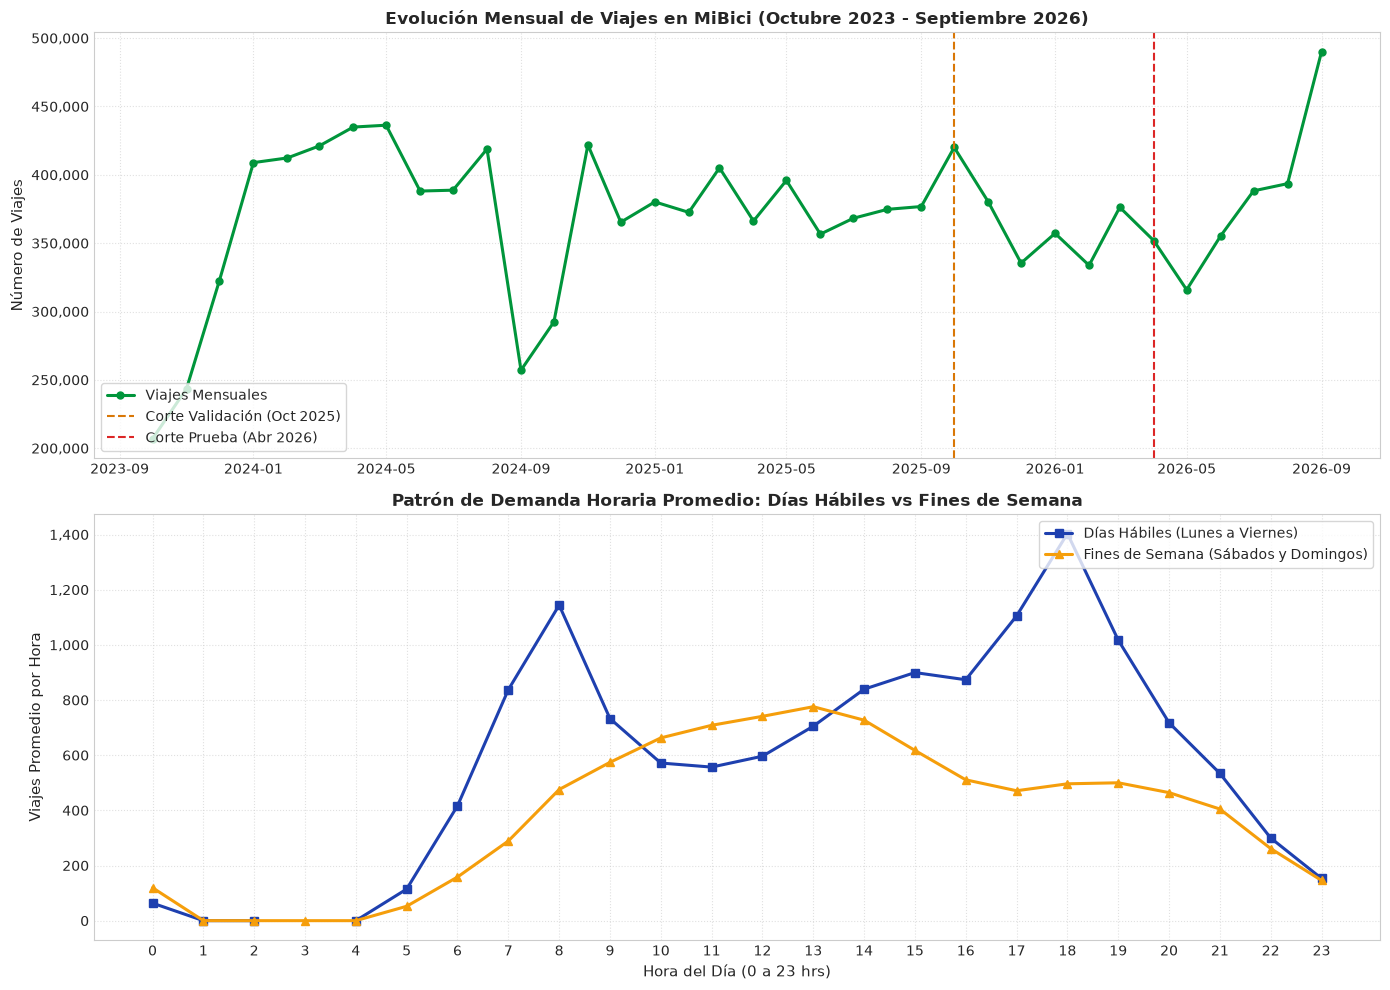

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. SERIE TEMPORAL MENSUAL
monthly_trips = df_dates.groupby("year_month").size()
month_timestamps = monthly_trips.index.to_timestamp()

axes[0].plot(
    month_timestamps,
    monthly_trips.values,
    marker="o",
    color="#00953B",
    linewidth=2.2,
    markersize=5,
    label="Viajes Mensuales",
)
axes[0].axvline(
    train_cutoff,
    color="#D97706",
    linestyle="--",
    linewidth=1.5,
    label="Corte Validación (Oct 2025)",
)
axes[0].axvline(
    val_cutoff, color="#DC2626", linestyle="--", linewidth=1.5, label="Corte Prueba (Abr 2026)"
)
axes[0].set_title(
    "Evolución Mensual de Viajes en MiBici (Octubre 2023 - Septiembre 2026)", fontweight="bold"
)
axes[0].set_ylabel("Número de Viajes")
axes[0].yaxis.set_major_formatter("{x:,.0f}")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="lower left", frameon=True)

# 2. PATRÓN HORARIO PROMEDIO (DÍA HÁBIL VS FIN DE SEMANA)
df_dates["hour"] = df_dates["started_at"].dt.hour
df_dates["is_weekend"] = df_dates["started_at"].dt.dayofweek >= 5

hourly_pivot = df_dates.groupby(["hour", "is_weekend"]).size().unstack()
# Normalizar por el número de días para obtener promedio diario aproximado
num_weekdays = np.busday_count(min_date.date(), max_date.date())
num_weekends = (max_date.date() - min_date.date()).days - num_weekdays

hourly_avg_weekday = hourly_pivot[False] / max(num_weekdays, 1)
hourly_avg_weekend = hourly_pivot[True] / max(num_weekends, 1)

hours = np.arange(24)
axes[1].plot(
    hours,
    hourly_avg_weekday,
    marker="s",
    color="#1E40AF",
    linewidth=2.2,
    label="Días Hábiles (Lunes a Viernes)",
)
axes[1].plot(
    hours,
    hourly_avg_weekend,
    marker="^",
    color="#F59E0B",
    linewidth=2.2,
    label="Fines de Semana (Sábados y Domingos)",
)
axes[1].set_title(
    "Patrón de Demanda Horaria Promedio: Días Hábiles vs Fines de Semana", fontweight="bold"
)
axes[1].set_xlabel("Hora del Día (0 a 23 hrs)")
axes[1].set_ylabel("Viajes Promedio por Hora")
axes[1].set_xticks(hours)
axes[1].yaxis.set_major_formatter("{x:,.0f}")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

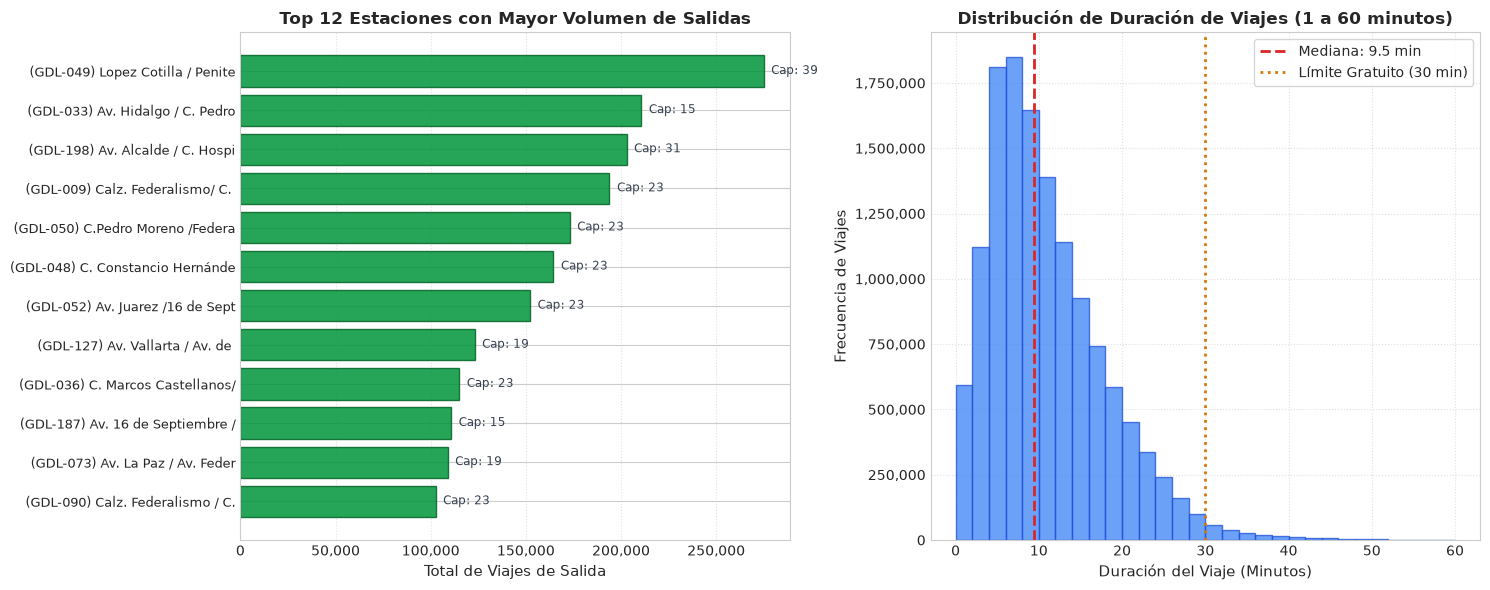

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 3. TOP 12 ESTACIONES MÁS UTILIZADAS
top_stations = df_dates["origin_station_id"].value_counts().head(12).reset_index()
top_stations.columns = ["station_id", "trip_count"]

# Unir nombre de la estación desde nomenclatura
nomenclature = pd.read_csv(DATA_NOMENCLATURE)
top_stations = top_stations.merge(
    nomenclature[["id", "name", "dpcapacity"]], left_on="station_id", right_on="id", how="left"
)
top_stations["short_name"] = top_stations["name"].str.slice(0, 32)

y_pos = np.arange(len(top_stations))
bars = axes[0].barh(
    y_pos, top_stations["trip_count"], color="#00953B", alpha=0.85, edgecolor="#006427"
)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_stations["short_name"], fontsize=9.5)
axes[0].invert_yaxis()  # Estación más activa arriba
axes[0].set_xlabel("Total de Viajes de Salida")
axes[0].set_title("Top 12 Estaciones con Mayor Volumen de Salidas", fontweight="bold")
axes[0].xaxis.set_major_formatter("{x:,.0f}")
axes[0].grid(axis="x", linestyle=":", alpha=0.6)

# Añadir etiqueta con capacidad
for idx, bar in enumerate(bars):
    cap = top_stations.loc[idx, "dpcapacity"]
    axes[0].text(
        bar.get_width() + 4000,
        bar.get_y() + bar.get_height() / 2,
        f"Cap: {cap}",
        va="center",
        fontsize=8.5,
        color="#374151",
    )

# 4. HISTOGRAMA DE DURACIÓN DE VIAJES (TÍPICOS: 1 A 60 MIN)
axes[1].hist(
    typical_duration[typical_duration <= 60],
    bins=30,
    color="#3B82F6",
    edgecolor="#1D4ED8",
    alpha=0.75,
)
axes[1].axvline(
    typical_duration.median(),
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {typical_duration.median():.1f} min",
)
axes[1].axvline(30, color="#D97706", linestyle=":", linewidth=2, label="Límite Gratuito (30 min)")
axes[1].set_title("Distribución de Duración de Viajes (1 a 60 minutos)", fontweight="bold")
axes[1].set_xlabel("Duración del Viaje (Minutos)")
axes[1].set_ylabel("Frecuencia de Viajes")
axes[1].yaxis.set_major_formatter("{x:,.0f}")
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

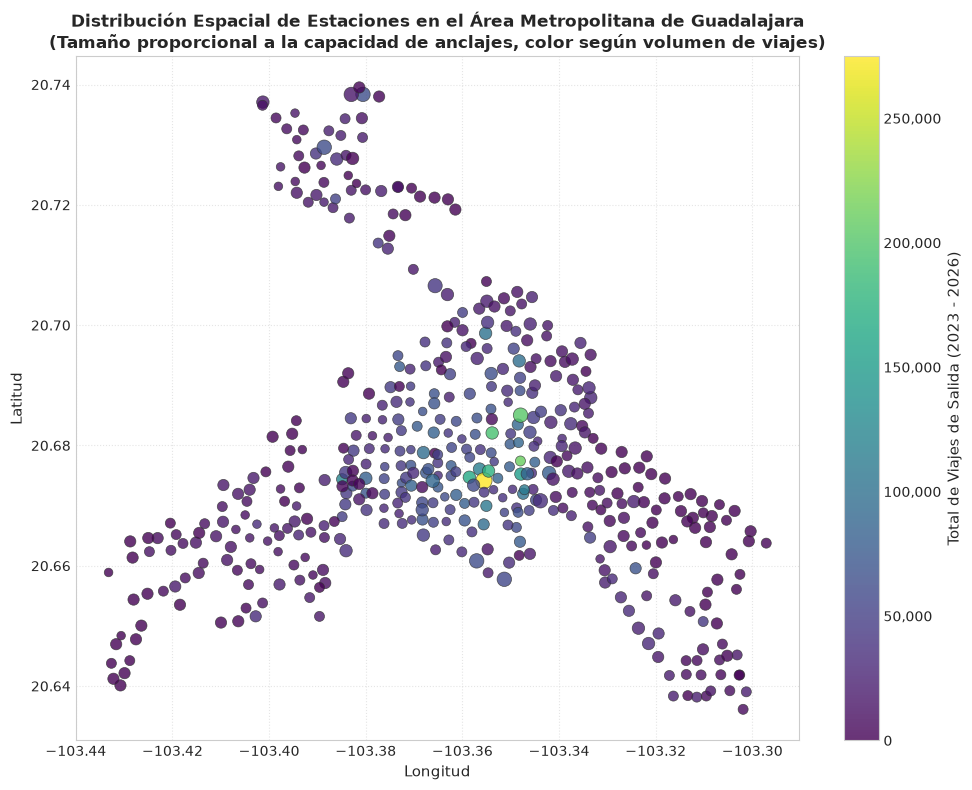

In [8]:
# 5. DISPERSIÓN ESPACIAL DE ESTACIONES Y CAPACIDAD
# Calcular viajes totales de origen por estación
station_trips = df_dates["origin_station_id"].value_counts().reset_index()
station_trips.columns = ["id", "total_trips"]

geo_stations = nomenclature.merge(station_trips, on="id", how="left").fillna({"total_trips": 0})
# Filtrar coordenadas válidas en el área metropolitana de Guadalajara
geo_stations = geo_stations[
    (geo_stations["latitude"] > 20.5)
    & (geo_stations["latitude"] < 20.8)
    & (geo_stations["longitude"] > -103.5)
    & (geo_stations["longitude"] < -103.2)
]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    geo_stations["longitude"],
    geo_stations["latitude"],
    c=geo_stations["total_trips"],
    cmap="viridis",
    s=geo_stations["dpcapacity"] * 3.5,
    alpha=0.8,
    edgecolors="#333333",
    linewidth=0.5,
)

cbar = plt.colorbar(scatter)
cbar.set_label("Total de Viajes de Salida (2023 - 2026)")
cbar.formatter.set_useOffset(False)
cbar.ax.yaxis.set_major_formatter("{x:,.0f}")

plt.title(
    "Distribución Espacial de Estaciones en el Área Metropolitana de Guadalajara\n(Tamaño proporcional a la capacidad de anclajes, color según volumen de viajes)",
    fontweight="bold",
)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 8. Conclusiones y Próximos Pasos en el Pipeline de MLOps

### Hallazgos Principales del Análisis Exploratorio
1. **Volumetría Robusta y Limpieza Exitosa:**
   * El rango de 36 meses (octubre 2023 a septiembre 2026) consolida **13,313,152 viajes** y **473 estaciones activas**.
   * Menos del **0.02%** de los registros presentan duraciones anómalas (negativas o mayores a 8 horas), las cuales son filtradas de manera determinista sin mermar la representatividad.
2. **Dinámica Bimodal en Días Hábiles:**
   * Se observan dos picos de demanda muy marcados de lunes a viernes: el pico matutino (7:00 a 9:00 AM) y el pico vespertino (6:00 a 8:00 PM), con un valle intermedio al mediodía.
   * Los fines de semana la curva es unimodal y aplanada, desplazando la máxima utilización hacia las 11:00 AM - 2:00 PM (uso predominantemente recreativo/turístico).
3. **Hiper-concentración Espacial:**
   * Un grupo selecto de estaciones céntricas (e.g. *López Cotilla / Penitenciaría*, *Federalismo / Angulo*, *Alcalde / Hospital*) concentra volúmenes masivos de viajes (> 200,000 viajes cada una), convirtiéndose en focos críticos de rebalanceo (P2).

---

### Próximos Pasos en el Repositorio de MLOps
* **Fase 1 (`mibici.features`):** Construcción del generador de *lags* temporales ($t-1\text{h}, t-2\text{h}, t-24\text{h}, t-168\text{h}$) y la cuadrícula completa de estaciones $\times$ horas imputando demanda cero.
* **Fase 2 (`mibici.modeling.train`):**
  * Entrenamiento del modelo base de regresión para **P1** (LightGBM Regressor con TimeSeriesSplit).
  * Entrenamiento del clasificador de riesgo para **P2** (LightGBM Classifier con función de pérdida ponderada para clases desbalanceadas).
  * Pipeline de agrupamiento para **P3** (K-Means y análisis de silueta para segmentación funcional).
* **Fase 3 (MLflow & Versionado):** Registro de métricas (MAE, RMSE, WAPE, PR-AUC) y artefactos de modelo versionados con DVC en Google Cloud Storage.
* **Fase 4 (Despliegue):** Exposición de inferencias batch mediante API con FastAPI y tablero operativo para cuadrillas de rebalanceo.